(liquid-eos)=
# Liquid Equation of State

We use the DFT-LDA liquid silica model from {cite:t}`Karki2007`. This dataset covers the pressure-volume-temperature range of interest for the melt curve and shock and release experiments: 2.2 to 5.4 g/cm$^3$ and 3000 to 6000 K.

Karki presents a fit to the 3000 K isotherm and a function for the thermal pressure term fitted to the dataset. Here, we add a bound for 0 pressure at 1 g/cm$^3$ and fit a fifth order polynomial to the 3000 K isotherm and use the Karki thermal pressure model.

The implementation for the PVT EOS model is shown in `load_liquid_model.py`.

In [1]:
%%capture 
## This cell loads the modules, data, and EOS parameters
## capture magic function hides the output; comment out to see diagnostic info during data load
## Run executable notebook for output

# Z Hugoniot fit
#qtz_liq_hug = 'NEW'#'NEW' or 'KD09' or `KD13` # pick which quartz Hugoniot equation
%run -i scripts/set_paths
%run -i scripts/load_modules
%run -i scripts/load_silica_data
%run -i scripts/define_mc
%run -i scripts/define_eos
%run -i scripts/calibrate_decaying_shocks.py
%run -i scripts/load_vapor_domes.py
%run -i scripts/load_liquid_model.py
%run -i scripts/load_solid_models.py
%run -i scripts/hugoniot-entropy.py # includes entropies
%run -i scripts/intersection.py # intersection function
#%run -i scripts/odr_models.py # ODR and model functions # do not need here
%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors

# this notebook's figure name tag
tag = 'LEOS-'


In [2]:
#%run -i scripts/hugoniot-calcs.py # includes entropies
print(fs_hug_liq.S)

[2986.05347088 2986.99105496 2987.92844306 ... 8758.32036547 8758.4403657
 8758.56035711]


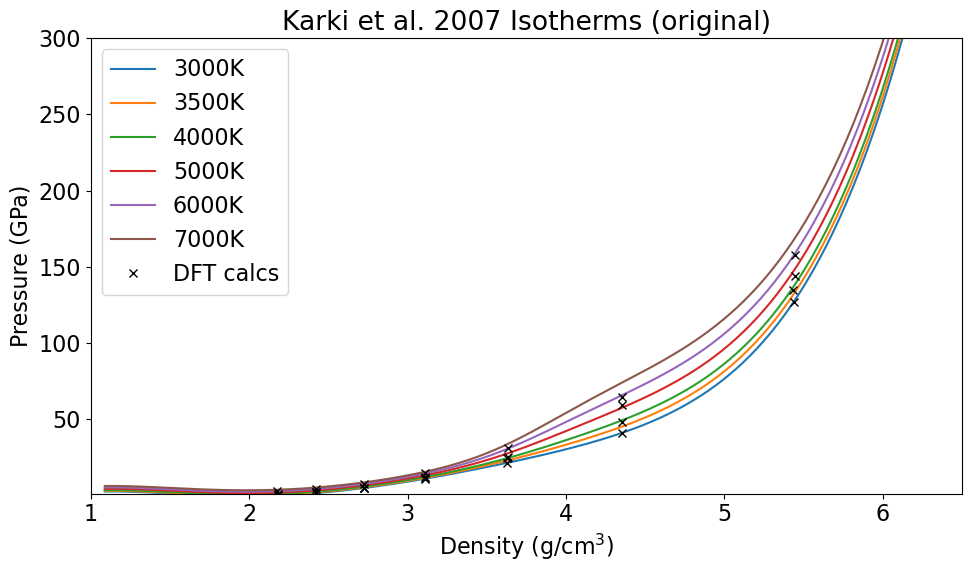

In [3]:
plt.figure(figsize=(10, 6))
plt.rcParams.update({'font.size': 16})
plt.plot(karkiorig.rhoarr,karkiorig.p3000,'-',label='3000K')
plt.plot(karkiorig.rhoarr,karkiorig.p3500,'-',label='3500K')
plt.plot(karkiorig.rhoarr,karkiorig.p4000,'-',label='4000K')
plt.plot(karkiorig.rhoarr,karkiorig.p5000,'-',label='5000K')
plt.plot(karkiorig.rhoarr,karkiorig.p6000,'-',label='6000K')
plt.plot(karkiorig.rhoarr,karkiorig.p7000,'-',label='7000K')
plt.plot(karki.rho,karki.P,'kx',label='DFT calcs')
plt.ylim(1,300)
#plt.yscale("log")
plt.xlim(1,6.5)
plt.legend()
plt.xlabel(r'Density (g/cm$^3$)')
plt.ylabel('Pressure (GPa)')
plt.title('Karki et al. 2007 Isotherms (original)')
plt.tight_layout()
plt.savefig(outputfigpath+'K1-karki-dft-and-fits.pdf')
plt.show()

```{figure} ./figs/dot.png
---
width: 1px
name: Karki-isotherms
---
Isotherms in silica liquid from PVT model from {cite}`Karki2007`. Black $\times$ are calculated DFT points using LDA.
```

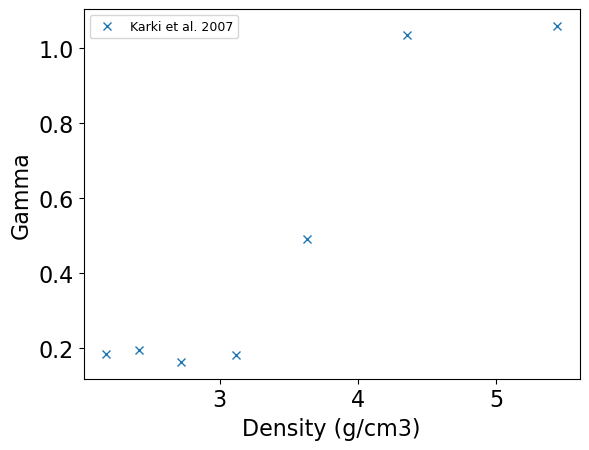

In [4]:
plt.plot(karkigcvorig.rho,karkigcvorig.gamma,'x',label='Karki et al. 2007')
plt.xlabel('Density (g/cm3)')
plt.ylabel('Gamma')
plt.legend(fontsize=lfss)



```{figure} ./figs/dot.png
---
width: 1px
name: Karki-gamma
---
Grüneisen parameter in silica liquid from {cite:t}`Karki2007`, where each point is the average from 3000-6000 K data. Note that the high-density limit approaches 2/3 {cite}`McCoy2016,Li2018`. The peak in $\gamma$ corresponds to increasing the coordination number of Si-O in the fluid, and a similar feature is seen in forsterite (Mg$_2$SiO$_4$ in {cite:t}`Davies2020`). At low densities, the plateau near 0.2 is also observed in other ab initio studies {cite}`DeKoker2009`. We use the Grüneisen parameter to link isentropes from the Hugoniot to the vapor curve (see {numref}`liquid-gamma-model`).
```

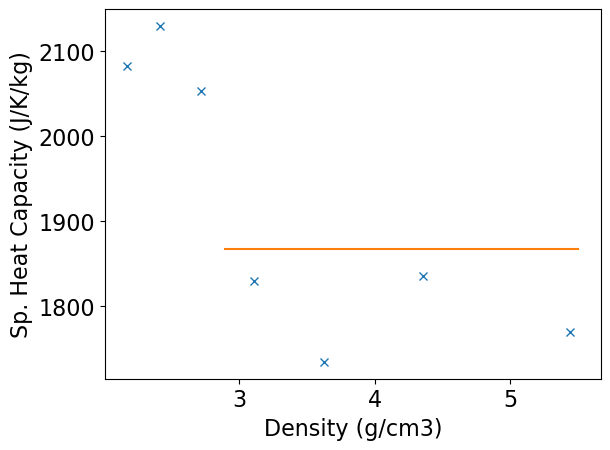

In [5]:
# cv values from Karki are averaged between 3000 and 6000 K
plt.plot(karkigcvorig.rho,karkigcvorig.cv,'x')
plt.xlabel('Density (g/cm3)')
plt.ylabel('Sp. Heat Capacity (J/K/kg)')
plt.plot([2.9,5.5],[karkipvt.cv,karkipvt.cv])
#plt.plot([2.9,5.5],[1825,1825]) # we used this value for calculating dS
plt.show()

```{figure} ./figs/dot.png
---
width: 1px
name: Karki-cv
---
Specific heat capacity in silica liquid from {cite}`Karki2007`. We use a constant heat capacity to calculate the entropy difference between isotherms at the reference density.
```

## Compare Karki et al. 2007 liquid model to shock Hugoniots

The Karki et al. liquid model is offset from the shock Hugoniot data. We derived a constant shift in density between DFT and the shock Hugoniots for fused silica, quartz, and coesite in {ref}`lda-vs-data`. That constant shift in density is applied to the Karki model to define a liquidus curve density.


In [6]:
print('The DFT liquid model is shifted by '+str(lda_liquid_density_shift)+' g/cm3.')

The DFT liquid model is shifted by -0.1460732034660399 g/cm3.


In [7]:
print(karkipvt.cv)

1868.065842251552


## Gamma model

The Grueneisen parameter in the liquid EOS model uses the fits provided by {cite:t}`Ocampo2025`. 


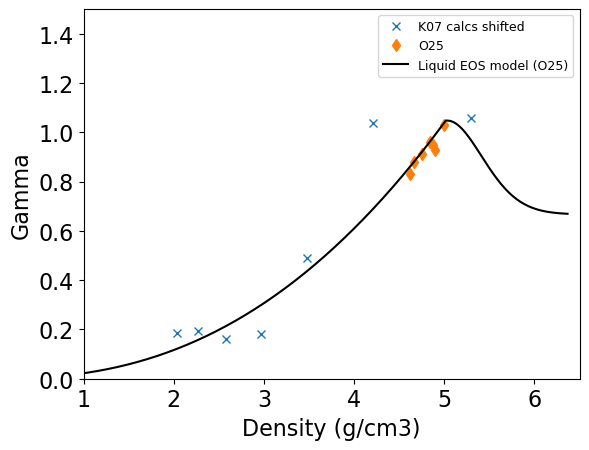

In [8]:

plt.plot(karkigcvorig.rho+lda_liquid_density_shift,karkigcvorig.gamma,'x',label='K07 calcs shifted')
#plt.plot(sftpvt.rhoarr,sftpvt.garr,'--',label='Sft EOS model')

plt.plot(shockdat[iO25fs.i].rho,shockdat[iO25fs.i].gamma,'d',label='O25')

v00=0.4627
vvv = (1/v00)/karkipvt.rhoarr
gammaO25low = 0.14*np.pow(vvv,-2.39)
#plt.plot(karkipvt.rhoarr,gammaO25low)
# OCampo et al. 2025
A00=0.381
B00=5.033
C00=0.1056
gammaO25 = 2/3 + A00*np.exp(-np.pow(np.log(karkipvt.rhoarr/B00)/C00,2))
ind = np.where(karkipvt.rhoarr>B00)[0]
#plt.plot(karkipvt.rhoarr[ind],gammaO25[ind])

plt.plot(karkipvt.rhoarr,karkipvt.garr,'k-',label='Liquid EOS model (O25)')

#plt.plot([3.7,4.62,4.87,5.0],[.5,.83,.95,1.03],'bd')
plt.xlabel('Density (g/cm3)')
plt.ylabel('Gamma')
plt.xlim(1,6.5)
plt.ylim(0,1.5)
plt.legend(fontsize=lfss)
plt.show()


```{figure} ./figs/dot.png
---
width: 1px
name: liquid-gamma-model
---
Grüneisen parameter model used for silica liquid are fits from {cite:t}`Ocampo2025`. Calculated DFT points from {cite:t}`Karki2007` are shifted in density.
```

## Calculated isentropes

At the liquid reference point density (4.645 g/cm3), we calculate the specific entropy at different temperatures using a constant specific heat capacity ({numref}`Karki-cv`) from our reference tie point. The Grüneisen parameter is used to calculate the temperature-density isentropes originating from the reference density.

To calculate the entropy at the reference density:<br>
$S(T) = [ln(T)-ln(T_{\rm ref})]*c_v + S_{\rm ref}$

To calculate the temperature along an isentrope:<br>
$ln(T_{i}) = \gamma(\rho_i)*[ln(\rho_{i})-ln(\rho_{i-1})] + ln(T_{i-1})$







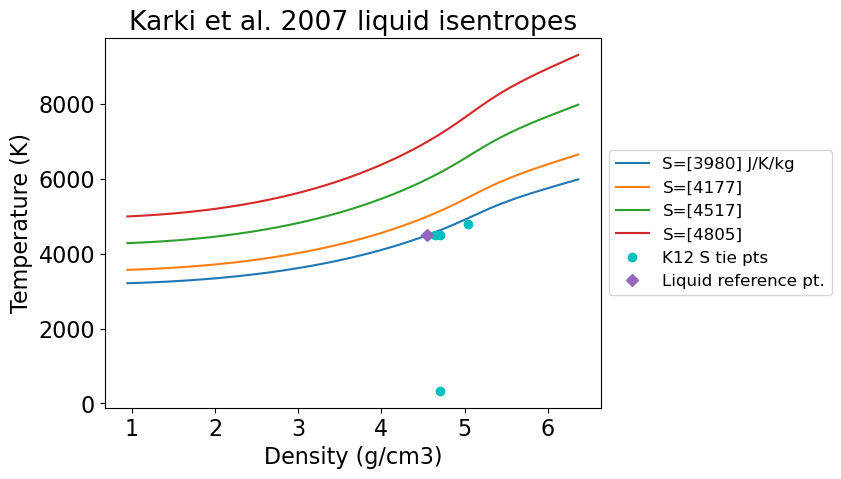

In [9]:
iii = np.where(karkipvt.stempsarr == 4500)[0]
plt.plot(karkipvt.rhoarr,karkipvt.st4500,label='S='+str(np.int_(np.round(karkipvt.svalsarr[iii])))+' J/K/kg')
iii = np.where(karkipvt.stempsarr == 5000)[0]
plt.plot(karkipvt.rhoarr,karkipvt.st5000,label='S='+str(np.int_(np.round(karkipvt.svalsarr[iii]))))
iii = np.where(karkipvt.stempsarr == 6000)[0]
plt.plot(karkipvt.rhoarr,karkipvt.st6000,label='S='+str(np.int_(np.round(karkipvt.svalsarr[iii]))))
iii = np.where(karkipvt.stempsarr == 7000)[0]
plt.plot(karkipvt.rhoarr,karkipvt.st7000,label='S='+str(np.int_(np.round(karkipvt.svalsarr[iii]))))


plt.xlabel('Density (g/cm3)')
plt.ylabel('Temperature (K)')
plt.title('Karki et al. 2007 liquid isentropes')
# Kraus et al. 2012 Entropy Tie Points for SiO2
# density T
plt.plot([1/0.2125,1/0.2125,1/0.2153,1/0.1983],[334,4500,4500,4800],'co',label='K12 S tie pts')
# new reference point
plt.plot(karkipvt.refpt[0],karkipvt.refpt[2],'D',label='Liquid reference pt.')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5),fontsize=12)
plt.show()

```{figure} ./figs/dot.png
---
width: 1px
name: Karki-isentropes
---
Isentropes in silica liquid using the reference point, constant specific heat capacity, and model Grüneisen parameter.
```

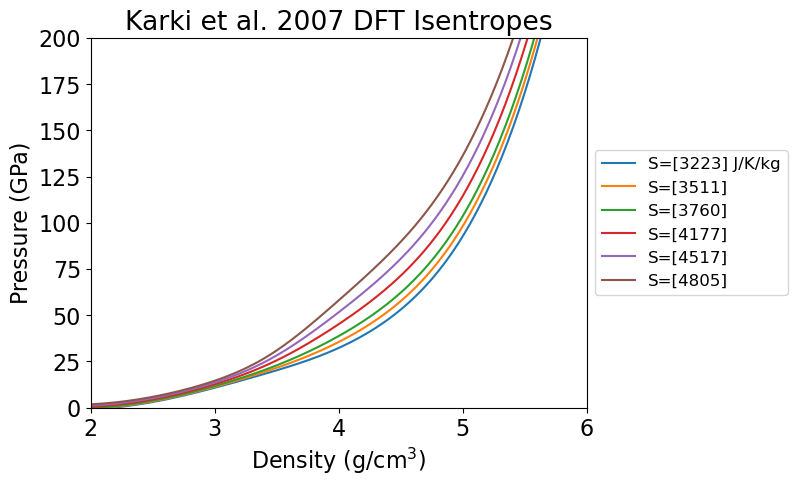

In [10]:
#plt.plot(karkipvt.rhoarr,karkipvt.sp2500)
iii = np.where(karkipvt.stempsarr == 3000)[0]
plt.plot(karkipvt.rhoarr,karkipvt.sp3000,label='S='+str(np.int_(np.round(karkipvt.svalsarr[iii])))+' J/K/kg')
iii = np.where(karkipvt.stempsarr == 3500)[0]
plt.plot(karkipvt.rhoarr,karkipvt.sp3500,label='S='+str(np.int_(np.round(karkipvt.svalsarr[iii]))))
iii = np.where(karkipvt.stempsarr == 4000)[0]
plt.plot(karkipvt.rhoarr,karkipvt.sp4000,label='S='+str(np.int_(np.round(karkipvt.svalsarr[iii]))))
iii = np.where(karkipvt.stempsarr == 5000)[0]
plt.plot(karkipvt.rhoarr,karkipvt.sp5000,label='S='+str(np.int_(np.round(karkipvt.svalsarr[iii]))))
iii = np.where(karkipvt.stempsarr == 6000)[0]
plt.plot(karkipvt.rhoarr,karkipvt.sp6000,label='S='+str(np.int_(np.round(karkipvt.svalsarr[iii]))))
iii = np.where(karkipvt.stempsarr == 7000)[0]
plt.plot(karkipvt.rhoarr,karkipvt.sp7000,label='S='+str(np.int_(np.round(karkipvt.svalsarr[iii]))))
plt.ylim(0,200)
plt.xlim(2,6)
plt.xlabel(r'Density (g/cm$^3$)')
plt.ylabel('Pressure (GPa)')
plt.title('Karki et al. 2007 DFT Isentropes')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5),fontsize=12)
plt.show()

```{figure} ./figs/dot.png
---
width: 1px
name: Karki-isentropes2
---
Isentropes in silica liquid in pressure-density space.
```

## Absolute entropy tie point

The reference point entropy is chosen so that the model intersects the 1-bar boiling point on the silica vapor curve.

From {cite:t}`Connolly2016`, the 1-bar boiling point for liquid SiO$_2$ is about T=3130$\pm$30 K and S=3560$\pm$100 J/K/kg.

The tie point is defined in the `define_eos.py` file.

In [11]:
print('Liquid reference point:')
print('Density (g/cm3):           ', liquid_reference_point[0])
print('Pressure (GPa):            ', liquid_reference_point[1])
print('Temperature (K):           ', liquid_reference_point[2])
print('Specific Entropy (J/K/kg): ', liquid_reference_point[3])
print(' ')
iii = np.where(karkipvt.stempsarr == 4500)[0]
print('1-bar boiling isentrope (J/K/kg): ', int(np.round(karkipvt.svalsarr[iii])[0]))


Liquid reference point:
Density (g/cm3):            4.550678911282411
Pressure (GPa):             70
Temperature (K):            4500
Specific Entropy (J/K/kg):  3980
 
1-bar boiling isentrope (J/K/kg):  3980


[2.1245689] [2618.10367482]
3257.5949476539645 [3510.52810086] -252.9331532094966
[2.05428127] [3351.71595978]
C16 cyan 3658.3418012770985 [3980.] -321.6581987229015
[1.89724896] [3322.14581629]
3620.072908144253 [3980.] -359.9270918557472
[1.86667777] [4422.39929466]
C16 cyan 4020.5732242501676 [4517.40905298] -496.835828725139
[1.43627116] [4339.54807135]
4162.124323523275 [4517.40905298] -355.28472945203157


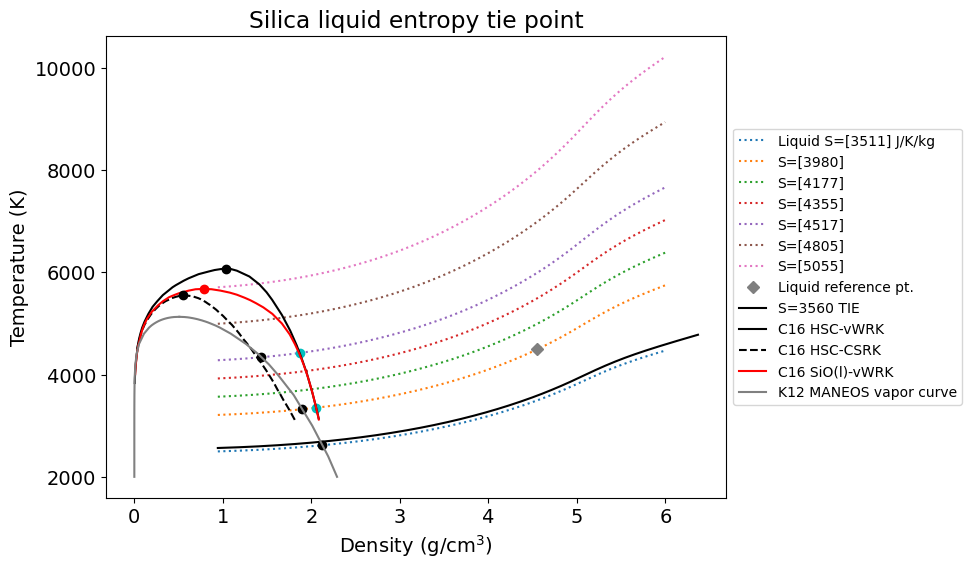

In [12]:

plt.figure(figsize=(8, 6))
plt.rcParams.update({'font.size': 14})

# plot Karki DFT Isentropes
ind = np.where(karkipvt.rhoarr < 6)[0]
iii = np.where(karkipvt.stempsarr == 3500)[0]
plt.plot(karkipvt.rhoarr[ind],karkipvt.st3500[ind],':',label='Liquid S='+str(np.int_(np.round(karkipvt.svalsarr[iii])))+' J/K/kg')


x,y=intersection(karkipvt.rhoarr[ind],karkipvt.st3500[ind],kdome.rho_l,kdome.T)
print(x,y)
plt.plot(x,y,'ko')
K12sint = np.interp(y[0],np.flip(kdome.T),np.flip(kdome.ent_l))
print(K12sint,karkipvt.svalsarr[iii],K12sint-karkipvt.svalsarr[iii][0])



iii = np.where(karkipvt.stempsarr == 4500)[0]
plt.plot(karkipvt.rhoarr[ind],karkipvt.st4500[ind],':',label='S='+str(np.int_(np.round(karkipvt.svalsarr[iii]))))

x,y=intersection(karkipvt.rhoarr[ind],karkipvt.st4500[ind],C16bsrho,C16bstemp)
print(x,y)
plt.plot(x,y,'co')
C16sint = np.interp(y[0],C16hight,C16highs)
print('C16 cyan',C16sint,karkipvt.svalsarr[iii],C16sint-karkipvt.svalsarr[iii][0])

x,y=intersection(karkipvt.rhoarr[ind],karkipvt.st4500[ind],kdome.rho_l,kdome.T)
print(x,y)
plt.plot(x,y,'ko')
K12sint = np.interp(y[0],np.flip(kdome.T),np.flip(kdome.ent_l))
print(K12sint,karkipvt.svalsarr[iii],K12sint-karkipvt.svalsarr[iii][0])


iii = np.where(karkipvt.stempsarr == 5000)[0]
plt.plot(karkipvt.rhoarr[ind],karkipvt.st5000[ind],':',label='S='+str(np.int_(np.round(karkipvt.svalsarr[iii]))))
iii = np.where(karkipvt.stempsarr == 5500)[0]
plt.plot(karkipvt.rhoarr[ind],karkipvt.st5500[ind],':',label='S='+str(np.int_(np.round(karkipvt.svalsarr[iii]))))
iii = np.where(karkipvt.stempsarr == 6000)[0]
plt.plot(karkipvt.rhoarr[ind],karkipvt.st6000[ind],':',label='S='+str(np.int_(np.round(karkipvt.svalsarr[iii]))))


x,y=intersection(karkipvt.rhoarr[ind],karkipvt.st6000[ind],C16bsrho,C16bstemp)
print(x,y)
plt.plot(x,y,'co')
C16sint = np.interp(y[0],C16hight,C16highs)
print('C16 cyan',C16sint,karkipvt.svalsarr[iii],C16sint-karkipvt.svalsarr[iii][0])

x,y=intersection(karkipvt.rhoarr[ind],karkipvt.st6000[ind],kdome.rho_l,kdome.T)
print(x,y)
plt.plot(x,y,'ko')
K12sint = np.interp(y[0],np.flip(kdome.T),np.flip(kdome.ent_l))
print(K12sint,karkipvt.svalsarr[iii],K12sint-karkipvt.svalsarr[iii][0])


iii = np.where(karkipvt.stempsarr == 7000)[0]
plt.plot(karkipvt.rhoarr[ind],karkipvt.st7000[ind],':',label='S='+str(np.int_(np.round(karkipvt.svalsarr[iii]))))
x,y=intersection(karkipvt.rhoarr[ind],karkipvt.st7000[ind],C16bsrho,C16bstemp)
#print(x,y)
C16sint = np.interp(y[0],C16hight,C16highs)
#print(C16sint,karkipvt.svalsarr[iii])

iii = np.where(karkipvt.stempsarr == 8000)[0]
plt.plot(karkipvt.rhoarr[ind],karkipvt.st8000[ind],':',label='S='+str(np.int_(np.round(karkipvt.svalsarr[iii]))))
x,y=intersection(karkipvt.rhoarr[ind],karkipvt.st8000[ind],C16bsrho,C16bstemp)
#print(x,y)
C16sint = np.interp(y[0],C16hight,C16highs)
#print(C16sint,karkipvt.svalsarr[iii])

# new reference point
plt.plot(karkipvt.refpt[0],karkipvt.refpt[2],'D',label='Liquid reference pt.')

# PLOT TIE ISENTROPE
sval=3560
karkipvt.isenval_liquid(sval)
plt.plot(karkipvt.rhoarr,karkipvt.isenval_t,'k-',label='S=3560 TIE')

plt.plot(C16bsrho,C16bstemp,'k-',label='C16 HSC-vWRK')
plt.plot(C16bdrho,C16bdtemp,'k--',label='C16 HSC-CSRK')
plt.plot(C16rsrho,C16rstemp,'r-',label='C16 SiO(l)-vWRK')

plt.plot(kdome.rho_l,kdome.T,'-',color='grey',label='K12 MANEOS vapor curve')
plt.plot(kdome.rho_v,kdome.T,'-',color='grey')

# critical points
plt.plot(1.036,6074,'ko')
plt.plot(.555,5548,'ko')
plt.plot(.782,5675,'ro')

# check the function
#karkipvt.isenval_liquid(3560)
#plt.plot(karkipvt.rhoarr,karkipvt.isenval_t,'--')
#karkipvt.isenval_liquid(4352)
#plt.plot(karkipvt.rhoarr,karkipvt.isenval_t,'--')

plt.xlabel(r'Density (g/cm$^3$)')
plt.ylabel('Temperature (K)')
plt.title('Silica liquid entropy tie point')

plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize=10)
plt.show()

```{figure} ./figs/dot.png
---
width: 1px
name: entropy-tie-point
---
The absolute entropy in the liquid model is tied to the boiling point at 1 bar and quartz Hugoniot liquidus crossing. Example vapor curves from {cite:t}`Connolly2016` and calculated isentropes using the model from {cite:t}`Karki2007`. The critical points from C16 have S_cp=5322-5404 J/K/kg. This model using a constant heat capacity has slightly larger entropy at the critical points.
```

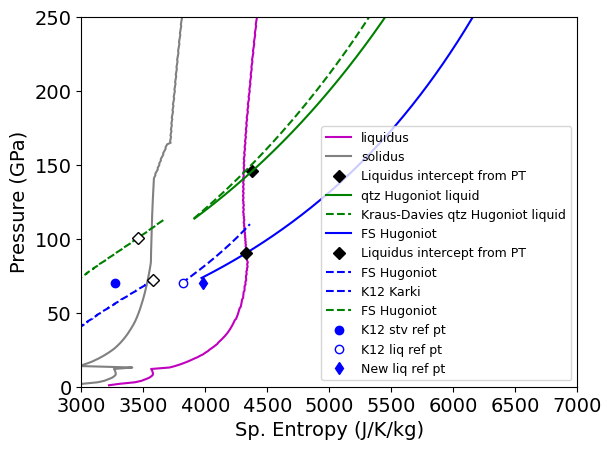

In [13]:

plt.plot(stsmcsmooth.S_l,stsmcsmooth.P,'m-',label='liquidus')
plt.plot(stsmcsmooth.S_s,stsmcsmooth.P,'-',color='grey',label='solidus')
plt.plot(np.interp(qtz_liquidus_P,qtz_hug_liq.P,qtz_hug_liq.S),qtz_liquidus_P,'kD',label='Liquidus intercept from PT')
ind = np.where(qtz_hug_liq.P > qtz_wiggle_P2)[0]
plt.plot(qtz_hug_liq.S[ind],qtz_hug_liq.P[ind],'g-',label='qtz Hugoniot liquid')

plt.plot(qtz_hug_liq_K12.S[ind],qtz_hug_liq_K12.P[ind],'g--',label='Kraus-Davies qtz Hugoniot liquid')


ind = np.where(fs_hug_liq.P >fs_wiggle_P2)[0]
plt.plot(fs_hug_liq.S[ind],fs_hug_liq.P[ind],'b-',label='FS Hugoniot')
plt.plot(np.interp(fs_liquidus_P,fs_hug_liq.P,fs_hug_liq.S),fs_liquidus_P,'kD',label='Liquidus intercept from PT')

ind = np.where(fs_hug_stv.P <fs_wiggle_P2)[0]
plt.plot(fs_hug_stv.S[ind],fs_hug_stv.P[ind],'b--',label='FS Hugoniot')
plt.plot(np.interp(fs_solidus_P, fs_hug_stv.P,fs_hug_stv.S ), fs_solidus_P,'kD',mfc='white')

#ind = np.where(fs_hug_liq_karki.P >fs_wiggle_P2)[0]
#plt.plot(fs_hug_liq_karki.S[ind],fs_hug_liq_karki.P[ind],'b:',label='FS Karki')

ind = np.where((fs_hug_liq_K12.P >70) & (fs_hug_liq_K12.P <110))[0]
plt.plot(fs_hug_liq_K12.S[ind],fs_hug_liq_K12.P[ind],'b--',label='K12 Karki')

ind = np.where(qtz_hug_solid.P <qtz_wiggle_P2)[0]
plt.plot(qtz_hug_solid.S[ind],qtz_hug_solid.P[ind],'g--',label='FS Hugoniot')
plt.plot(np.interp(qtz_solidus_P, qtz_hug_solid.P,qtz_hug_solid.S ), qtz_solidus_P,'kD',mfc='white')

plt.plot(stv_reference_point[3],stv_reference_point[1],'bo',label='K12 stv ref pt')
plt.plot(krausrefpt[3],krausrefpt[1],'bo',mfc='white',label='K12 liq ref pt')
plt.plot(liquid_reference_point[3],liquid_reference_point[1],'bd',label='New liq ref pt')

#plt.plot(kdome.ent_l,kdome.P,'-',color='grey',label='K12 MANEOS vapor curve')
#plt.plot(kdome.ent_v,kdome.P,'-',color='grey')
#plt.plot( 5150,5130,'o',color='grey',markersize=5)
#plt.plot(3820,70,'bD')
plt.ylim(0.0,250)
plt.xlim(3000,7000)
plt.xlabel('Sp. Entropy (J/K/kg)')
plt.ylabel('Pressure (GPa)')
plt.legend(fontsize=lfss,loc='lower right')


In [14]:
print(-1.414*Rgas/(sio2mol/1000)-229)

-424.6626000699033


```{figure} ./figs/dot.png
---
width: 1px
name: entropy-tie-point2
---
The absolute entropy in the liquid model agrees with quartz Hugoniot liquidus crossing from Kraus-Davies.
```

[np.float64(4.550678911282411), 70, 4500, 3980]


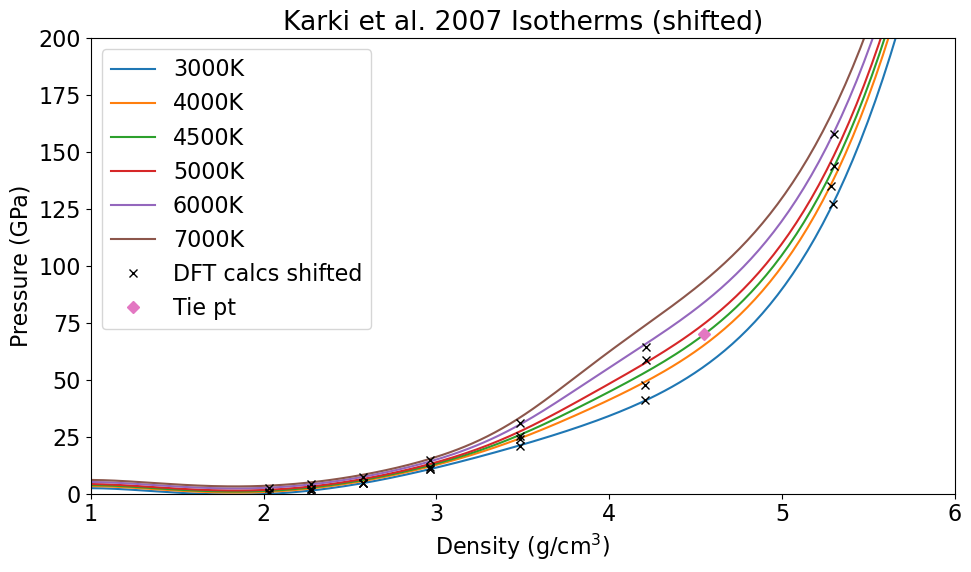

In [15]:
plt.figure(figsize=(10, 6))
plt.rcParams.update({'font.size': 16})
plt.plot(karkipvt.rhoarr,karkipvt.p3000,'-',label='3000K')
#plt.plot(karkipvt.rhoarr,karkipvt.p3500,'-',label='3500K')
plt.plot(karkipvt.rhoarr,karkipvt.p4000,'-',label='4000K')
plt.plot(karkipvt.rhoarr,karkipvt.p4500,'-',label='4500K')
plt.plot(karkipvt.rhoarr,karkipvt.p5000,'-',label='5000K')
plt.plot(karkipvt.rhoarr,karkipvt.p6000,'-',label='6000K')
plt.plot(karkipvt.rhoarr,karkipvt.p7000,'-',label='7000K')
plt.plot(karki.rho+lda_liquid_density_shift,karki.P,'kx',label='DFT calcs shifted')

if 0:
    # check the isotherm function works
    tval=7000
    karkipvt.isotherm_liquid(tval)
    plt.plot(karkipvt.rhoarr,karkipvt.isotherm_p,'c:',linewidth=5)
    tval=6000
    karkipvt.isotherm_liquid(tval)
    plt.plot(karkipvt.rhoarr,karkipvt.isotherm_p,'c:',linewidth=5)

plt.plot(karkipvt.refpt[0],karkipvt.refpt[1],'D',label='Tie pt')
print(karkipvt.refpt)
plt.ylim(0,200)
plt.xlim(1,6)
plt.legend()
plt.xlabel(r'Density (g/cm$^3$)')
plt.ylabel('Pressure (GPa)')
plt.title('Karki et al. 2007 Isotherms (shifted)')
plt.tight_layout()
plt.show()


## Calculate dU along the isentropes

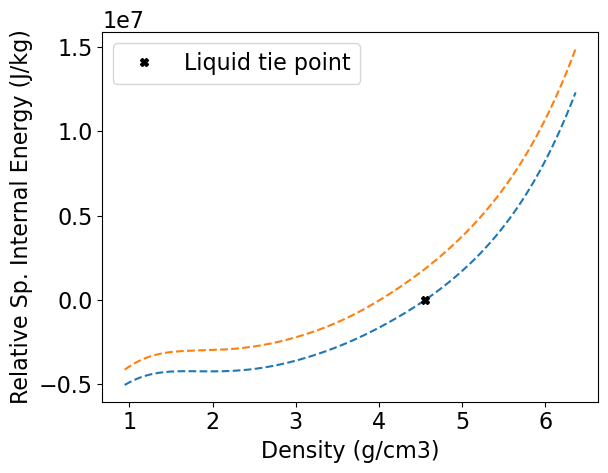

In [16]:

karkipvt.isenval_liquid(karkipvt.refpt[3])
#plt.plot(karkipvt.rhoarr,karkipvt.isenval_t,'--')
plt.plot(karkipvt.rhoarr,karkipvt.isenval_u,'--')
karkipvt.isenval_liquid(4352)
#plt.plot(karkipvt.rhoarr,karkipvt.isenval_t,'--')
plt.plot(karkipvt.rhoarr,karkipvt.isenval_u,'--')
plt.plot(karkipvt.refpt[0],0,'kX',label='Liquid tie point')
plt.xlabel('Density (g/cm3)')
plt.ylabel('Relative Sp. Internal Energy (J/kg)')
plt.legend()
plt.show()


## Calculated liquidus

Using the proposed melt curve, calculate the state variables along the liquidus using the Karki et al. liquid model.


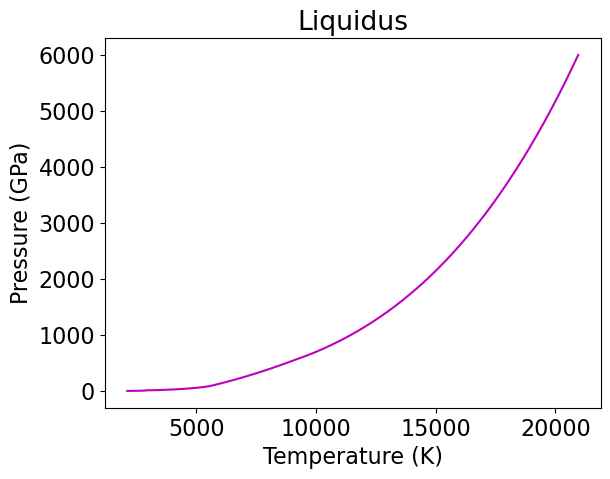

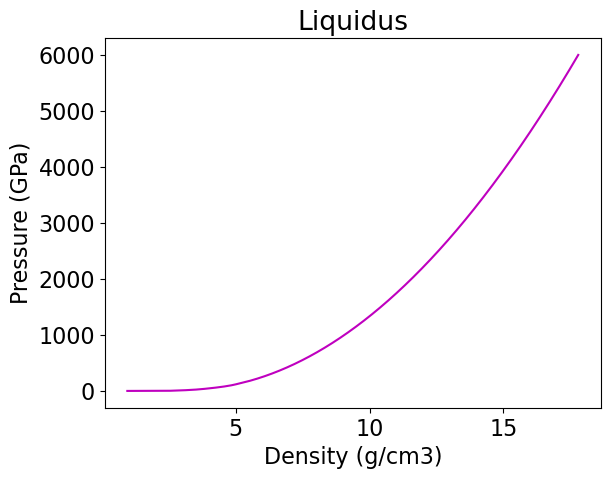

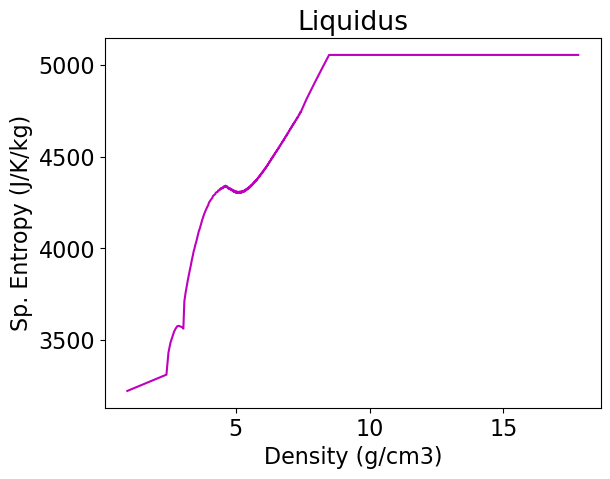

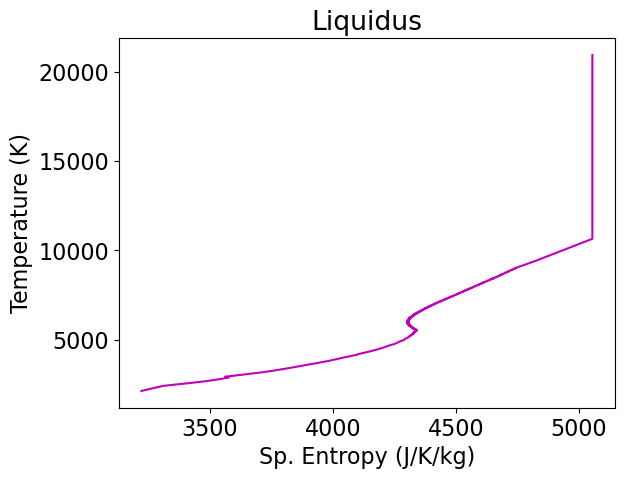

In [17]:
plt.plot(stsmcsmooth.T,stsmcsmooth.P,'m-')
plt.xlabel('Temperature (K)')
plt.ylabel('Pressure (GPa)')
plt.title('Liquidus')
plt.show()
plt.plot(stsmcsmooth.rho,stsmcsmooth.P,'m-')
plt.xlabel('Density (g/cm3)')
plt.ylabel('Pressure (GPa)')
plt.title('Liquidus')
plt.show()
plt.plot(stsmcsmooth.rho,stsmcsmooth.S_l,'m-')
plt.xlabel('Density (g/cm3)')
plt.ylabel('Sp. Entropy (J/K/kg)')
plt.title('Liquidus')
plt.show()
plt.plot(stsmcsmooth.S_l,stsmcsmooth.T,'m-')
plt.xlabel('Sp. Entropy (J/K/kg)')
plt.ylabel('Temperature (K)')
plt.title('Liquidus')
plt.show()


```{figure} ./figs/dot.png
---
width: 1px
name: liquidus-model
---
State variables along the model liquidus from this work.
```

## Problems with the model

We need a new liquid EOS model with PVTS that is appropriate for densities greater than 5 g/cm3.



0 4400.922071897982 5027.3122
fs  0 shot20 94.18660988337355 5027.3122 4995.945309 IR4 IR4
1 4537.987752584057 6703.340637
fs  1 shot21 101.74287645992194 6703.340637 4455.373225 IR4 IR3
2 4491.019747101814 4573.230527
fs  2 shot22 99.09285426949843 4573.230527 4278.540428 IR4 IR4
3 4176.429165264379 4200.1755
fs  3 shot23 82.90944976418177 4200.1755 4172.764445 IR4 IR4
4 4202.973880495417 4483.578691
fs  4 shot25 84.17608214986328 4483.578691 3496.421395 IR2 IR2
5 4179.062655302834 4611.0908
fs  5 shot31 83.03434421043941 4611.0908 4558.900819 IR4 IR4
fs  6 shot40 56.528901686378255 -999.0 -999.0 nan nan
7 3234.944541456848 4670.915
fs  7 shot41 54.32443426562305 4670.915 3359.670084 IR4 IR4
fs  8 shot60 87.37011891423583 5239.0 -999.0 streak decay
fs  9 shot50 68.06379203710938 5170.0 -999.0 streak decay
qtz  0 shot14 87.43147985491223 4661.0 -999.0 streak nan
qtz  1 shot26 124.32252836116284 5329.4 4096.2 streak streak
2 2864.7219119456645
qtz  2 shot27 65.10390400961398 3412.766828

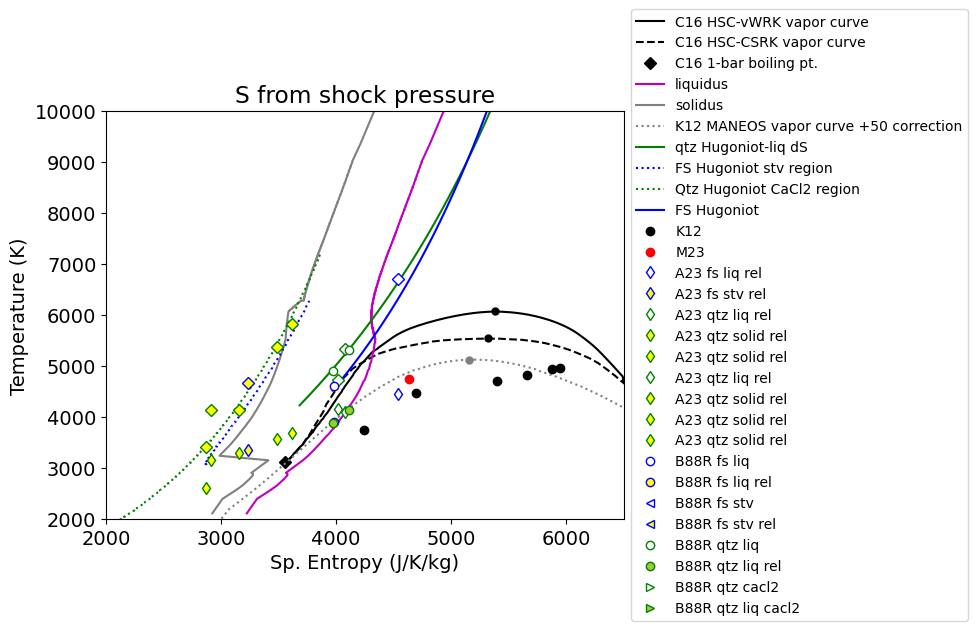

In [18]:
# calculate S from pressure

for ifig in [1]:
    fig1=False
    fig2=False
    fig3=False
    if ifig==1:
        fig1=True # Kraus et al 2012 plot + Connolly
    if ifig==2:
        fig2=True # all points - what a mess
    if ifig==3:   
        fig3=True  # only points away from inversion zone
    plt.figure(figsize=(10, 6))
    plt.rcParams.update({'font.size': 14})

    if 1:
        #plot Connolly calcs
        b = np.argsort(C16highs)
        plt.plot(C16highs[b],C16hight[b],'-',color='black',label='C16 HSC-vWRK vapor curve')
        plt.plot(5382,6074,'o',color='black',markersize=5)
        plt.plot(C16lows,C16lowt,'--',color='black',label='C16 HSC-CSRK vapor curve')
        plt.plot(5322,5548,'o',color='black',markersize=5)
        #plt.plot(C16sils,C16silt,'-',color='orangered',label='C16 SiO(l)-vWRK')
        #plt.plot(5403,5675,'o',color='orangered')
        # plot boiling point at 1 bar
        # note Kraus S_vap too small
        plt.plot([3554,7460],[3130,3130],'kD',label='C16 1-bar boiling pt.')
    
    if fig1:
        plt.plot(stsmcsmooth.S_l,stsmcsmooth.T,'m-',label='liquidus')
        plt.plot(stsmcsmooth.S_s,stsmcsmooth.T,'-',color='grey',label='solidus')

    #plt.plot(kdome.ent_l,kdome.T,'-',color='grey',label='K12 MANEOS vapor curve')
    #plt.plot(kdome.ent_v,kdome.T,'-',color='grey')
    plt.plot(kdome.ent_l+50,kdome.T,':',color='grey',label='K12 MANEOS vapor curve +50 correction')
    plt.plot(kdome.ent_v+50,kdome.T,':',color='grey')#
    plt.plot( 5150,5130,'o',color='grey',markersize=5)
    
    if fig1 or fig3:
        #ind = np.where(qtz_hug_cacl2.P < 115)[0]
        #plt.plot(qtz_hug_cacl2.S[ind],qtz_hug_cacl2.T[ind],'g--',label='qtz Hugoniot-CaCl2 region')
        ind = np.where(qtz_hug_liq.P >100)[0]
        plt.plot(qtz_hug_liq.S[ind],qtz_hug_liq.T[ind],'g-',label='qtz Hugoniot-liq dS')
        ind = np.where(qtz_hug_liq.P >100)[0]
        #plt.plot(qtz_hug_liq_karki.S[ind],qtz_hug_liq_karki.T[ind],'m-',label='qtz Hugoniot-liq karki')
        #ind = np.where((qtz_hug_sft.P >110) & (qtz_hug_sft.P <140))[0]
        #plt.plot(qtz_hug_sft.S[ind],qtz_hug_sft.T[ind],'g:',label='qtz Hugoniot-sft region')
    if 0:
        ind = np.where(fs_hug_stv.P < 80)[0]
        plt.plot(fs_hug_stv.S[ind],fs_hug_stv.T[ind],'b--',label='fs Hugoniot-stv region')
        ind = np.where(fs_hug_liq.P > 70)[0]
        plt.plot(fs_hug_liq.S[ind],fs_hug_liq.T[ind],'b-',label='FS liq NEW')
        #plt.plot(fs_hug_mix.S,fs_hug_mix.T,'b-',linewidth=4,label='FS mix NEW')

    # This one
    if 1:
        # plot Kaitlyn's fused silica as from thesis with model entropies USING PRESSURE MATCH
        splot = np.zeros(len(shockdat_list[A23fs['id']].P))
        for ii in range(len(splot)):
            if shockdat_list[A23fs['id']].T_rel[ii]>0:
                if shockdat_list[A23fs['id']].P[ii]>72:   
                    splot[ii]= np.interp(np.asarray(shockdat_list[A23fs['id']].P[ii]),fs_hug_liq.P,fs_hug_liq.S)
                    shockdat_list[A23fs['id']].S[ii] = splot[ii]
                    print(ii,splot[ii],shockdat_list[A23fs['id']].T[ii])
                    if shockdat_list[A23fs['id']].exp_id[ii] == 'shot21':   
                        plt.errorbar(splot[ii],shockdat_list[A23fs['id']].T_rel[ii],fmt='bd',mfc='white',label='A23 fs liq rel')
                        plt.errorbar(splot[ii],shockdat_list[A23fs['id']].T[ii],fmt='bD',mfc='white')
                else:
                    splot[ii]= np.interp(np.asarray(shockdat_list[A23fs['id']].P[ii]),fs_hug_stv.P,fs_hug_stv.S)
                    shockdat_list[A23fs['id']].S[ii] = splot[ii]
                    print(ii,splot[ii],shockdat_list[A23fs['id']].T[ii])
                    plt.errorbar(splot[ii],shockdat_list[A23fs['id']].T_rel[ii],fmt='bd',mfc='yellow',label='A23 fs stv rel')
                    plt.errorbar(splot[ii],shockdat_list[A23fs['id']].T[ii],fmt='bD',mfc='yellow')
            print('fs ',ii,shockdat_list[A23fs['id']].exp_id[ii],shockdat_list[A23fs['id']].P[ii],shockdat_list[A23fs['id']].T[ii],shockdat_list[A23fs['id']].T_rel[ii],shockdat_list[A23fs['id']].T_source[ii],shockdat_list[A23fs['id']].T_rel_source[ii])
        
    if 1:
        # plot Kaitlyn's quartz as from thesis with model entropies USING PRESSURE MATCH
        splot = np.zeros(len(shockdat_list[A23qtz['id']].P))
        for ii in range(len(splot)):
            if shockdat_list[A23qtz['id']].T_rel[ii]>0:
                if shockdat_list[A23qtz['id']].P[ii]<115:
                    splot[ii]= np.interp(np.asarray(shockdat_list[A23qtz['id']].P[ii]),qtz_hug_solid.P,qtz_hug_solid.S)
                    shockdat_list[A23qtz['id']].S[ii] = splot[ii]
                    print(ii,splot[ii])
                    plt.errorbar(splot[ii],shockdat_list[A23qtz['id']].T_rel[ii],fmt='gd',mfc='yellow',label='A23 qtz solid rel')
                    plt.errorbar(splot[ii],shockdat_list[A23qtz['id']].T[ii],fmt='gD',mfc='yellow')
                else:
                    splot[ii]= np.interp(np.asarray(shockdat_list[A23qtz['id']].P[ii]),qtz_hug_liq.P,qtz_hug_liq.S)
                    shockdat_list[A23qtz['id']].S[ii] = splot[ii]
                    plt.errorbar(splot[ii],shockdat_list[A23qtz['id']].T_rel[ii],fmt='gd',mfc='white',label='A23 qtz liq rel')
                    plt.errorbar(splot[ii],shockdat_list[A23qtz['id']].T[ii],fmt='gD',mfc='white')
            print('qtz ',ii,shockdat_list[A23qtz['id']].exp_id[ii],shockdat_list[A23qtz['id']].P[ii],shockdat_list[A23qtz['id']].T[ii],shockdat_list[A23qtz['id']].T_rel[ii],shockdat_list[A23qtz['id']].T_source[ii],shockdat_list[A23qtz['id']].T_rel_source[ii])
        #plt.errorbar(splot,shockdat_list[A23qtz['id']].T,fmt='gD',mfc='white',label='A23 qtz cacl2')
            

    if 1:
        # All release temps for FS
        # plot Boslough fused silica USING PRESSURE MATCH
        splot = np.zeros(len(shockdat_list[B88RRfs['id']].T))
        tplot = np.zeros(len(shockdat_list[B88RRfs['id']].T))
        trelplot = np.zeros(len(shockdat_list[B88RRfs['id']].T))
        for ii in range(len(shockdat_list[B88RRfs['id']].T)):
            if shockdat_list[B88RRfs['id']].P[ii]>70:
                splot[ii]= np.interp(np.asarray(shockdat_list[B88RRfs['id']].P[ii]),fs_hug_liq.P,fs_hug_liq.S)
                tplot[ii]=shockdat_list[B88RRfs['id']].T[ii]
                trelplot[ii]=shockdat_list[B88RRfs['id']].T_rel[ii]
                shockdat_list[B88RRfs['id']].S[ii] = splot[ii]
                #print('liq',ii,splot[ii])
        ind = np.where(trelplot > 0)[0]
        plt.errorbar(splot[ind],tplot[ind],fmt='bo',mfc='white',label='B88R fs liq')
        plt.errorbar(splot[ind],trelplot[ind],fmt='bo',mfc='yellow',label='B88R fs liq rel')
        splot = np.zeros(len(shockdat_list[B88RRfs['id']].T))
        tplot = np.zeros(len(shockdat_list[B88RRfs['id']].T))
        trelplot = np.zeros(len(shockdat_list[B88RRfs['id']].T))
        #for ii in range(len(shockdat_list[B88RRfs['id']].T)):
            #if shockdat_list[B88RRfs['id']].P[ii]<70:
                #splot[ii]= np.interp(np.asarray(shockdat_list[B88RRfs['id']].P[ii]),fs_hug_stv.P,fs_hug_stv.S)
                #tplot[ii]=shockdat_list[B88RRfs['id']].T[ii]
                #trelplot[ii]=shockdat_list[B88RRfs['id']].T_rel[ii]
                #shockdat_list[B88RRfs['id']].S[ii] = splot[ii]
                #print('stv',ii,splot[ii],tplot[ii],trelplot[ii])
        ind = np.where(trelplot > 0)[0]
        plt.errorbar(splot[ind],tplot[ind],fmt='b<',mfc='white',label='B88R fs stv')
        plt.errorbar(splot[ind],trelplot[ind],fmt='b<',mfc='yellow',label='B88R fs stv rel')

    if 1:
        # All release temps for QUARTZ 
        # plot Boslough fused silica USING PRESSURE MATCH
        splot = np.zeros(len(shockdat_list[B88RRqtz['id']].T))
        tplot = np.zeros(len(shockdat_list[B88RRqtz['id']].T))
        trelplot = np.zeros(len(shockdat_list[B88RRqtz['id']].T))
        for ii in range(len(shockdat_list[B88RRqtz['id']].T)):
            if shockdat_list[B88RRqtz['id']].P[ii]>115:
                splot[ii]= np.interp(np.asarray(shockdat_list[B88RRqtz['id']].P[ii]),qtz_hug_liq.P,qtz_hug_liq.S)
                tplot[ii]=shockdat_list[B88RRqtz['id']].T[ii]
                trelplot[ii]=shockdat_list[B88RRqtz['id']].T_rel[ii]
                shockdat_list[B88RRqtz['id']].S[ii] = splot[ii]
        ind = np.where(trelplot > 0)[0]
        plt.errorbar(splot[ind],tplot[ind],fmt='go',mfc='white',label='B88R qtz liq')
        plt.errorbar(splot[ind],trelplot[ind],fmt='go',mfc='yellowgreen',label='B88R qtz liq rel')
        splot = np.zeros(len(shockdat_list[B88RRqtz['id']].T))
        tplot = np.zeros(len(shockdat_list[B88RRqtz['id']].T))
        trelplot = np.zeros(len(shockdat_list[B88RRqtz['id']].T))
        #for ii in range(len(shockdat_list[B88RRqtz['id']].T)):
        #    if shockdat_list[B88RRqtz['id']].P[ii]<115:
        #        splot[ii]= np.interp(np.asarray(shockdat_list[B88RRqtz['id']].P[ii]),qtz_hug_cacl2.P,qtz_hug_cacl2.S)
        #        tplot[ii]=shockdat_list[B88RRqtz['id']].T[ii]
        #        trelplot[ii]=shockdat_list[B88RRqtz['id']].T_rel[ii]
        #        shockdat_list[B88RRqtz['id']].S[ii] = splot[ii]
        ind = np.where(trelplot > 0)[0]
        plt.errorbar(splot[ind],tplot[ind],fmt='g>',mfc='white',label='B88R qtz cacl2')
        plt.errorbar(splot[ind],trelplot[ind],fmt='g>',mfc='yellowgreen',label='B88R qtz liq cacl2')

    if 0:
        plt.errorbar([shotO1.S],[shotO1.T],fmt='g^',mfc='yellowgreen',label='Omega T')
        plt.errorbar([shotO1.S],[shotO1.T_rel],fmt='g^',mfc='white',label='Omega T_rel')
        plt.errorbar(shotK12.S,shotK12.T,fmt='gD',mfc='lightgrey',label='K12 T')
        plt.errorbar(shotK12.S,shotK12.T_rel,fmt='gd',mfc='lightgrey',label='K12 T_rel')
   
        

    plt.plot(fs_hug_stv.S,fs_hug_stv.T,'b:',label='FS Hugoniot stv region')
    plt.plot(qtz_hug_cacl2.S,qtz_hug_cacl2.T,'g:',label='Qtz Hugoniot CaCl2 region')
    ind = np.where(fs_hug_liq.P >fs_wiggle_P2)[0]
    plt.plot(fs_hug_liq.S[ind],fs_hug_liq.T[ind],'b-',label='FS Hugoniot')

    K12_P = np.asarray([318, 307, 277, 244, 172, 136])
    K12_Trel = np.asarray([4961, 4939, 4823, 4717, 4470, 3756])
    K12_S = np.interp(K12_P, qtz_hug_liq.P, qtz_hug_liq.S)
    plt.plot(K12_S,K12_Trel,'ko',label='K12')
    #Marius Millot email from Aug 30, 2023
    #looking at one shot exiting at 11.2 km/s
    #temperature is 0.41 eV.
    M23_us = np.asarray([11.2]) # km/s shock vel
    M23_Trel = np.asarray([0.41])*11604 # K
    M23_S = np.interp(M23_us, qtz_hug_liq.us, qtz_hug_liq.S)
    plt.plot(M23_S,M23_Trel,'ro',label='M23')
    

    
    plt.xlabel('Sp. Entropy (J/K/kg)')
    plt.ylabel('Temperature (K)')
    plt.title('S from shock pressure')
    plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize=10)


    
    if fig1:
        figname='Quartz-T-S-plot-SfromP-'
        plt.xlim([2000,6500])    
        plt.ylim([2000,10000])    
        #plt.xlim([2500,4000])    
        #plt.ylim([2000,4000])    
        #plt.yscale('log')


    #plt.plot(np.interp(qtz_liquidus_P,qtz_hug_liq.P,qtz_hug_liq.S),np.interp(qtz_liquidus_P,qtz_hug_liq.P,qtz_hug_liq.T),'kD')
    #plt.plot(np.interp(qtz_solidus_P,qtz_hug_cacl2.P,qtz_hug_cacl2.S),np.interp(qtz_liquidus_P,qtz_hug_liq.P,qtz_hug_liq.T),'kD')
    plt.tight_layout()
    plt.savefig(outputfigpath+figname+'.pdf')
    plt.show()

    #print(shockdat_list[A23qtz['id']].P)
    #print(sa23)


In [ ]:

# define constants
Rgas    = 8.314           # J/K/mol
sio2mol = 28.085+2*15.999 # g per formula unit


In [46]:
print(3*Rgas/(sio2mol/1000)*np.log(2))

287.74323814600064


In [27]:
print(np.log(2))

0.6931471805599453


In [29]:
print(sio2mol,Rgas)

60.083 8.314


In [37]:
print(3*.221*Rgas/sio2mol*1000)

91.74278914168734
